In [1]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
import os
import scipy.stats as stats
from scipy.special import logsumexp
import pandas as pd
import matplotlib.cm as cm
import math
import itertools
import random
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from random import random

from scipy.stats import linregress
from sklearn.linear_model import RANSACRegressor, LinearRegression
from scipy.stats import chi2_contingency, fisher_exact

import sys
sys.path.append('../src')

from em_clustering import (
    reassign_cells
)

from visualization import plot_overlap_matrix_figure

In [ ]:
tumor ="t31"
infilename = f"../data/{tumor}/{tumor}.bin_count_table_all_cells.txt"
bincounts = pd.read_csv(infilename, sep="\t")
bincounts_no_WGS = pd.read_csv(f"../data/{tumor}/{tumor}.bincounts_without_WGS_segmentation.txt", sep="\t")


In [3]:
# Use ALL cells instead of filtered cells
all_cell_names = [col for col in bincounts.columns if col not in ['chrom', 'abstart', 'abend', 'lengths','loc.start','loc.end']]
cells = pd.read_csv(f"../data/{tumor}/{tumor}.not_broken_final_list.txt", header=None)[0].values


In [4]:
def make_random_seeds(q_data, num_seeds=10):
    """Generate multiple random seeds for EM initialization."""
    Seeds = []
    for i in range(num_seeds):
        s = []
        for j in range(len(q_data)):
            l2 = q_data.loc[j].values
            mi, mx = min(l2), max(l2)
            s.append([random() * (mx - mi) + mi, random() * (mx - mi) + mi])
        Seeds.append(s)
    return Seeds

In [5]:
def alg_on_best_of_seeds(all_data, num_seeds=10):
    """Run EM algorithm on multiple seeds and return best result."""
    q_data = all_data/all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    best_log_lik = -np.inf
    for s in Seeds:
        print("Trying new seed")
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
        if log_lik > best_log_lik:
            best_log_lik = log_lik
            best_logprob_NK = logprob_NK
            best_mult_KV = mult_KV
    
    return best_logprob_NK, best_log_lik, best_mult_KV

In [6]:
def EM_algorithm(data, s, Min_Diff=0.001, Max_Iter=20):
    """Core EM algorithm implementation."""
    obs_NV = np.array(data)[:,:].T
    log_likelihood = -np.inf
    
    mult_KV = np.array(s).T
    mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]

    for _ in range(Max_Iter):
        logmult_KV = np.log(mult_KV)
        logprob_NK = np.dot(obs_NV, logmult_KV.T)
        logsum_N = [logsumexp(list(x)) for x in logprob_NK]
        logprob_NK = np.add(logprob_NK, -np.array(logsum_N)[:, np.newaxis])

        membership_NK = np.exp(logprob_NK)
        log_likelihood_last = log_likelihood
        log_likelihood = np.sum(logsum_N)

        mult_KV = np.dot(membership_NK.T, obs_NV)
        mult_KV = mult_KV / np.sum(mult_KV, axis=1)[:, np.newaxis]
        
        log_diff = abs(log_likelihood-log_likelihood_last)
        if log_diff < Min_Diff:
            break
            
    if log_diff > Min_Diff:
        return logprob_NK, -np.inf, mult_KV
    
    return logprob_NK, log_likelihood, mult_KV


In [7]:
def ratio_of_ratios(all_data, threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    logprob_NK, log_lik, mult_KV = alg_on_best_of_seeds(all_data)
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, p, dof, expected = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, mult_KV


In [8]:
def recursive_em_split_old(data, cell_list, mult_KV_param=None, threshold=3/4, max_depth=10, current_depth=0, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 50:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios(current_data, threshold, name)
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < 25 or len(cells_2) < 25:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split_new(
            data, cells_1, mult_KV[0], threshold, max_depth, current_depth + 1, name + "1"
        )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split_new(
            data, cells_2, mult_KV[1], threshold, max_depth, current_depth + 1, name + "2"
        )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


In [9]:
# Prepare data
data = bincounts[["chrom", "abstart", "abend"] + all_cell_names].copy()
data["lengths"] = data["abend"] - data["abstart"]
all_data = data[cells].copy()
data_no_WGS = bincounts_no_WGS[["chrom", "abstart", "abend"] + all_cell_names].copy()
data_no_WGS["lengths"] = data_no_WGS["abend"] - data_no_WGS["abstart"]
all_data_no_WGS = data_no_WGS[cells].copy()
with_broken = data[all_cell_names].copy()

In [10]:
# # 2. Run Recursive old EM Splitting (two independent runs)
# print("Running recursive EM split A...")
# final_populations_A = recursive_em_split_old(
#     all_data, cells, 
#     threshold=3/4, max_depth=10, name="A"
# )

In [11]:
num_seeds = 10
q_data = all_data/all_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [12]:
population_splits = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits.append((cells_1, cells_2))

In [13]:
for cells_1, cells_2 in population_splits:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 1743 cells in cluster 1, 790 cells in cluster 2
Population split: 1739 cells in cluster 1, 794 cells in cluster 2
Population split: 788 cells in cluster 1, 1745 cells in cluster 2
Population split: 788 cells in cluster 1, 1745 cells in cluster 2
Population split: 788 cells in cluster 1, 1745 cells in cluster 2
Population split: 1739 cells in cluster 1, 794 cells in cluster 2
Population split: 1743 cells in cluster 1, 790 cells in cluster 2
Population split: 1739 cells in cluster 1, 794 cells in cluster 2
Population split: 788 cells in cluster 1, 1745 cells in cluster 2
Population split: 1745 cells in cluster 1, 788 cells in cluster 2


In [14]:
pop_1, pop_2 = population_splits[0]

In [15]:
sub_data = all_data[pop_1]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [16]:
population_splits_1 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_1.append((cells_1, cells_2))

In [17]:
for cells_1, cells_2 in population_splits_1:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 85 cells in cluster 1, 1658 cells in cluster 2
Population split: 1672 cells in cluster 1, 71 cells in cluster 2
Population split: 145 cells in cluster 1, 1598 cells in cluster 2
Population split: 1663 cells in cluster 1, 80 cells in cluster 2
Population split: 86 cells in cluster 1, 1657 cells in cluster 2
Population split: 1650 cells in cluster 1, 93 cells in cluster 2
Population split: 1669 cells in cluster 1, 74 cells in cluster 2
Population split: 85 cells in cluster 1, 1658 cells in cluster 2
Population split: 83 cells in cluster 1, 1660 cells in cluster 2
Population split: 1653 cells in cluster 1, 90 cells in cluster 2


In [18]:
sub_data = all_data[pop_2]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [19]:
population_splits_2 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_2.append((cells_1, cells_2))

In [20]:
for cells_1, cells_2 in population_splits_2:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 365 cells in cluster 1, 425 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 365 cells in cluster 1, 425 cells in cluster 2
Population split: 365 cells in cluster 1, 425 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2
Population split: 425 cells in cluster 1, 365 cells in cluster 2


In [21]:
cells_1, cells_2 = population_splits_1[0]
#cells_3, cells_4 = population_splits_1[2]

In [22]:
len(cells_1), len(cells_2)

(85, 1658)

In [23]:
sub_data = all_data[cells_2]
num_seeds = 10
q_data = sub_data/sub_data.sum(axis=0)
Seeds = make_random_seeds(q_data, num_seeds)

best_log_lik = -np.inf
seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
for s in Seeds:
    print("Trying new seed")
    logprob_NK, log_lik, mult_KV = EM_algorithm(sub_data, s)
    seed_results["log_lik"].append(log_lik)
    seed_results["mult_KV"].append(mult_KV)
    seed_results["logprob_NK"].append(logprob_NK)
    if log_lik > best_log_lik:
        best_log_lik = log_lik
        best_logprob_NK = logprob_NK
        best_mult_KV = mult_KV

Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed
Trying new seed


In [24]:
population_splits_3 = []
for logprob_NK in seed_results["logprob_NK"]:
    cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
    cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
    cells_1 = [all_data.columns[i] for i in cluster1]
    cells_2 = [all_data.columns[i] for i in cluster2]
    population_splits_3.append((cells_1, cells_2))

In [25]:
for cells_1, cells_2 in population_splits_3:      
    print(f"Population split: {len(cells_1)} cells in cluster 1, {len(cells_2)} cells in cluster 2")

Population split: 498 cells in cluster 1, 1160 cells in cluster 2
Population split: 1161 cells in cluster 1, 497 cells in cluster 2
Population split: 497 cells in cluster 1, 1161 cells in cluster 2
Population split: 498 cells in cluster 1, 1160 cells in cluster 2
Population split: 1161 cells in cluster 1, 497 cells in cluster 2
Population split: 497 cells in cluster 1, 1161 cells in cluster 2
Population split: 498 cells in cluster 1, 1160 cells in cluster 2
Population split: 498 cells in cluster 1, 1160 cells in cluster 2
Population split: 1161 cells in cluster 1, 497 cells in cluster 2
Population split: 1160 cells in cluster 1, 498 cells in cluster 2


In [26]:
# Calculate pairwise overlap between all population splits
def calculate_overlap(cells_a, cells_b):
    """Calculate Jaccard similarity between two cell lists."""
    set_a = set(cells_a)
    set_b = set(cells_b)
    intersection = len(set_a & set_b)
    union = len(set_a | set_b)
    return intersection / union if union > 0 else 0

# Build overlap matrix for all splits
num_splits = len(population_splits)
overlap_matrix = np.zeros((num_splits, num_splits))

for i in range(num_splits):
    for j in range(num_splits):
        cells_1_i, cells_2_i = population_splits[i]
        cells_1_j, cells_2_j = population_splits[j]
        
        # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
        overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
        overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
        
        # Also compare cluster 1 to cluster 2 (in case labels are flipped)
        overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
        overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
        
        # Take the maximum overlap (accounting for potential label swapping)
        overlap_matrix[i, j] = max(
            (overlap_11 + overlap_22) / 2,
            (overlap_12 + overlap_21) / 2
        )


In [27]:
# Display overlap matrix
print("Overlap matrix between splits:")
print(overlap_matrix)


Overlap matrix between splits:
[[1.         0.99633366 0.99816111 0.99816111 0.99816111 0.99633366
  1.         0.99633366 0.99816111 0.99816111]
 [0.99633366 1.         0.99450246 0.99450246 0.99450246 1.
  0.99633366 1.         0.99450246 0.99450246]
 [0.99816111 0.99450246 1.         1.         1.         0.99450246
  0.99816111 0.99450246 1.         1.        ]
 [0.99816111 0.99450246 1.         1.         1.         0.99450246
  0.99816111 0.99450246 1.         1.        ]
 [0.99816111 0.99450246 1.         1.         1.         0.99450246
  0.99816111 0.99450246 1.         1.        ]
 [0.99633366 1.         0.99450246 0.99450246 0.99450246 1.
  0.99633366 1.         0.99450246 0.99450246]
 [1.         0.99633366 0.99816111 0.99816111 0.99816111 0.99633366
  1.         0.99633366 0.99816111 0.99816111]
 [0.99633366 1.         0.99450246 0.99450246 0.99450246 1.
  0.99633366 1.         0.99450246 0.99450246]
 [0.99816111 0.99450246 1.         1.         1.         0.99450246
  0.9

In [28]:
# Find the largest group of mutually high-consensus splits
consensus_threshold = 0.9

# Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
adjacency = (overlap_matrix > consensus_threshold).astype(int)

# Find connected components using a greedy approach
visited = set()
consensus_groups = []

for i in range(num_splits):
    if i in visited:
        continue
    
    # Start a new group with split i
    current_group = {i}
    candidates = set(range(num_splits)) - visited - {i}
    
    # Keep adding splits that have high consensus with ALL members of current group
    while candidates:
        added_any = False
        for candidate in list(candidates):
            # Check if candidate has high overlap with all members of current group
            if all(overlap_matrix[candidate, member] > consensus_threshold 
                   for member in current_group):
                current_group.add(candidate)
                candidates.remove(candidate)
                added_any = True
        
        # If no new splits were added, this group is complete
        if not added_any:
            break
    
    visited.update(current_group)
    consensus_groups.append(current_group)

# Find the largest consensus group
largest_group = max(consensus_groups, key=len)
print(f"Found {len(consensus_groups)} consensus groups")
print(f"Largest group has {len(largest_group)} splits: {largest_group}")

# Now create the consensus split from the largest group
consensus_split_indices = list(largest_group)
print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

# ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
# Use the first split as reference
reference_idx = consensus_split_indices[0]
ref_cells_1, ref_cells_2 = population_splits[reference_idx]

aligned_splits = []
for idx in consensus_split_indices:
    cells_1, cells_2 = population_splits[idx]
    
    # Check overlap with reference
    overlap_11 = calculate_overlap(cells_1, ref_cells_1)
    overlap_12 = calculate_overlap(cells_1, ref_cells_2)
    
    # If cluster 1 overlaps more with ref cluster 2, flip the labels
    if overlap_12 > overlap_11:
        aligned_splits.append((cells_2, cells_1))  # Flipped
    else:
        aligned_splits.append((cells_1, cells_2))  # Not flipped

# For each cell, count how many times it appears in cluster 1 vs cluster 2
cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

for cells_1, cells_2 in aligned_splits:
    for cell in cells_1:
        cell_votes[cell]['cluster1'] += 1
    for cell in cells_2:
        cell_votes[cell]['cluster2'] += 1

# Assign cells based on majority vote
consensus_cluster1 = []
consensus_cluster2 = []
unassigned_cells = []

vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

for cell in all_data.columns:
    votes = cell_votes[cell]
    total_votes = votes['cluster1'] + votes['cluster2']
    
    if votes['cluster1'] >= vote_threshold:
        consensus_cluster1.append(cell)
    elif votes['cluster2'] >= vote_threshold:
        consensus_cluster2.append(cell)
    else:
        unassigned_cells.append(cell)

print(f"\nConsensus results:")
print(f"Cluster 1: {len(consensus_cluster1)} cells")
print(f"Cluster 2: {len(consensus_cluster2)} cells")
print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")

Found 1 consensus groups
Largest group has 10 splits: {0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

Using 10 splits for consensus

Consensus results:
Cluster 1: 1739 cells
Cluster 2: 788 cells
Unassigned (stragglers): 6 cells


In [29]:
def consensus_split_population(all_data, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50):
    """
    Select split by descending log-likelihood, but require minimum consensus support.
    A candidate split is accepted if at least `min_consensus` fraction of OTHER splits
    have overlap >= `consensus_threshold` (flip-aware).
    """
    q_data = all_data / all_data.sum(axis=0)
    Seeds = make_random_seeds(q_data, num_seeds)

    split_records = []
    for s in Seeds:
        logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)

        # Skip non-converged / invalid runs
        if not np.isfinite(log_lik):
            continue

        diffs = np.array([x - y for x, y in logprob_NK])
        cluster1 = np.where(diffs > 0)[0]
        cluster2 = np.where(diffs < 0)[0]
        unassigned = np.where(diffs == 0)[0]

        cells_1 = [all_data.columns[i] for i in cluster1]
        cells_2 = [all_data.columns[i] for i in cluster2]
        unassigned_cells = [all_data.columns[i] for i in unassigned]

        # Keep only proper binary splits
        if len(cells_1) == 0 or len(cells_2) == 0:
            continue

        split_records.append({
            "log_lik": log_lik,
            "cells_1": cells_1,
            "cells_2": cells_2,
            "unassigned": unassigned_cells,
            "mult_KV": mult_KV
        })

    if len(split_records) == 0:
        print("No valid EM splits found.")
        return None, None, list(all_data.columns)

    # Sort by log-likelihood (highest first)
    split_records.sort(key=lambda r: r["log_lik"], reverse=True)

    # If only one valid split exists, accept it directly
    if len(split_records) == 1:
        chosen = split_records[0]
        print("Only one valid split found; accepting highest log-likelihood split.")
        print(f"Cluster 1: {len(chosen['cells_1'])} cells")
        print(f"Cluster 2: {len(chosen['cells_2'])} cells")
        print(f"Unassigned (stragglers): {len(chosen['unassigned'])} cells")
        return chosen["cells_1"], chosen["cells_2"], chosen["unassigned"]

    # Evaluate candidates in descending log-likelihood order
    n = len(split_records)
    for i, cand in enumerate(split_records):
        supporters = 0

        for j, other in enumerate(split_records):
            if i == j:
                continue

            c1_i, c2_i = cand["cells_1"], cand["cells_2"]
            c1_j, c2_j = other["cells_1"], other["cells_2"]

            overlap_11 = calculate_overlap(c1_i, c1_j)
            overlap_22 = calculate_overlap(c2_i, c2_j)
            overlap_12 = calculate_overlap(c1_i, c2_j)
            overlap_21 = calculate_overlap(c2_i, c1_j)

            overlap_score = max(
                (overlap_11 + overlap_22) / 2,
                (overlap_12 + overlap_21) / 2
            )

            if overlap_score >= consensus_threshold:
                supporters += 1

        support_fraction = supporters / (n - 1)

        if support_fraction >= min_consensus:
            print(
                f"Selected split rank={i+1} by log-likelihood "
                f"(log_lik={cand['log_lik']:.4f}) with support={support_fraction:.3f}"
            )
            print(f"Cluster 1: {len(cand['cells_1'])} cells")
            print(f"Cluster 2: {len(cand['cells_2'])} cells")
            print(f"Unassigned (stragglers): {len(cand['unassigned'])} cells")
            return cand["cells_1"], cand["cells_2"], cand["unassigned"], cand["mult_KV"]

    print("No split met minimum consensus support in log-likelihood order.")
    return None, None, list(all_data.columns), None

In [30]:
# def consensus_split_population(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds=50):
#     q_data = all_data/all_data.sum(axis=0)
#     Seeds = make_random_seeds(q_data, num_seeds)

#     seed_results = {"log_lik": [], "mult_KV": [], "logprob_NK": []}
#     count = 1
#     for s in Seeds:
#         #print("Seed " + str(count))
#         logprob_NK, log_lik, mult_KV = EM_algorithm(all_data, s)
#         seed_results["log_lik"].append(log_lik)
#         seed_results["mult_KV"].append(mult_KV)
#         seed_results["logprob_NK"].append(logprob_NK)
#         count += 1
    
#     population_splits = []
#     for logprob_NK in seed_results["logprob_NK"]:
#         cluster1 = np.where(np.array([x-y for x,y in logprob_NK])>0)[0]
#         cluster2 = np.where(np.array([x-y for x,y in logprob_NK])<0)[0]
#         cells_1 = [all_data.columns[i] for i in cluster1]
#         cells_2 = [all_data.columns[i] for i in cluster2]
#         population_splits.append((cells_1, cells_2))
    
#     # Build overlap matrix for all splits
#     num_splits = len(population_splits)
#     overlap_matrix = np.zeros((num_splits, num_splits))

#     for i in range(num_splits):
#         for j in range(num_splits):
#             cells_1_i, cells_2_i = population_splits[i]
#             cells_1_j, cells_2_j = population_splits[j]
            
#             # Compare cluster 1 to cluster 1 and cluster 2 to cluster 2
#             overlap_11 = calculate_overlap(cells_1_i, cells_1_j)
#             overlap_22 = calculate_overlap(cells_2_i, cells_2_j)
            
#             # Also compare cluster 1 to cluster 2 (in case labels are flipped)
#             overlap_12 = calculate_overlap(cells_1_i, cells_2_j)
#             overlap_21 = calculate_overlap(cells_2_i, cells_1_j)
            
#             # Take the maximum overlap (accounting for potential label swapping)
#             overlap_matrix[i, j] = max(
#                 (overlap_11 + overlap_22) / 2,
#                 (overlap_12 + overlap_21) / 2
#             )
    
#     # Create adjacency matrix (1 if overlap > threshold, 0 otherwise)
#     adjacency = (overlap_matrix > consensus_threshold).astype(int)

#     # Find connected components using a greedy approach
#     visited = set()
#     consensus_groups = []

#     for i in range(num_splits):
#         if i in visited:
#             continue
        
#         # Start a new group with split i
#         current_group = {i}
#         candidates = set(range(num_splits)) - visited - {i}
        
#         # Keep adding splits that have high consensus with ALL members of current group
#         while candidates:
#             added_any = False
#             for candidate in list(candidates):
#                 # Check if candidate has high overlap with all members of current group
#                 if all(overlap_matrix[candidate, member] > consensus_threshold 
#                     for member in current_group):
#                     current_group.add(candidate)
#                     candidates.remove(candidate)
#                     added_any = True
            
#             # If no new splits were added, this group is complete
#             if not added_any:
#                 break
        
#         visited.update(current_group)
#         consensus_groups.append(current_group)

#     # Find the largest consensus group
#     largest_group = max(consensus_groups, key=len)
#     print(f"Found {len(consensus_groups)} consensus groups")
#     print(f"Largest group has {len(largest_group)} splits: {largest_group}")

#     if len(largest_group) < min_consensus * num_splits:
#         print("No sufficient consensus found among splits.")
#         return None, None, list(all_data.columns)

#     # Now create the consensus split from the largest group
#     consensus_split_indices = list(largest_group)
#     print(f"\nUsing {len(consensus_split_indices)} splits for consensus")

#     # ALIGN ALL SPLITS TO HAVE CONSISTENT LABELING
#     # Use the first split as reference
#     reference_idx = consensus_split_indices[0]
#     ref_cells_1, ref_cells_2 = population_splits[reference_idx]

#     aligned_splits = []
#     for idx in consensus_split_indices:
#         cells_1, cells_2 = population_splits[idx]
        
#         # Check overlap with reference
#         overlap_11 = calculate_overlap(cells_1, ref_cells_1)
#         overlap_12 = calculate_overlap(cells_1, ref_cells_2)
        
#         # If cluster 1 overlaps more with ref cluster 2, flip the labels
#         if overlap_12 > overlap_11:
#             aligned_splits.append((cells_2, cells_1))  # Flipped
#         else:
#             aligned_splits.append((cells_1, cells_2))  # Not flipped

#     # For each cell, count how many times it appears in cluster 1 vs cluster 2
#     cell_votes = defaultdict(lambda: {'cluster1': 0, 'cluster2': 0})

#     for cells_1, cells_2 in aligned_splits:
#         for cell in cells_1:
#             cell_votes[cell]['cluster1'] += 1
#         for cell in cells_2:
#             cell_votes[cell]['cluster2'] += 1

#     # Assign cells based on majority vote
#     consensus_cluster1 = []
#     consensus_cluster2 = []
#     unassigned_cells = []

#     vote_threshold = len(aligned_splits) * 0.8  # 80% agreement required

#     for cell in all_data.columns:
#         votes = cell_votes[cell]
#         total_votes = votes['cluster1'] + votes['cluster2']
        
#         if votes['cluster1'] >= vote_threshold:
#             consensus_cluster1.append(cell)
#         elif votes['cluster2'] >= vote_threshold:
#             consensus_cluster2.append(cell)
#         else:
#             unassigned_cells.append(cell)
#     print(f"\nConsensus results:")
#     print(f"Cluster 1: {len(consensus_cluster1)} cells")
#     print(f"Cluster 2: {len(consensus_cluster2)} cells")
#     print(f"Unassigned (stragglers): {len(unassigned_cells)} cells")    
        
#     return consensus_cluster1, consensus_cluster2, unassigned_cells

In [31]:
consensus_cluster1, consensus_cluster2, unassigned_cells, mult_KV = consensus_split_population(all_data)

Selected split rank=1 by log-likelihood (log_lik=-658671542.5187) with support=1.000
Cluster 1: 1743 cells
Cluster 2: 790 cells
Unassigned (stragglers): 0 cells


In [32]:
# sub_data1 = all_data[consensus_cluster1]
# sub_data2 = all_data[consensus_cluster2]

In [33]:
#cluser21, cluster22, unassigned2 = consensus_split_population(sub_data2)

In [34]:
#cluser11, cluster12, unassigned1 = consensus_split_population(sub_data1)

In [35]:
def ratio_of_ratios_new(all_data, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds = 50,threshold=4/5, name=""):
    """Ratio of ratios analysis for population splitting."""
    cells_1, cells_2, unassigned, mult_KV = consensus_split_population(all_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds)

    if cells_1 is None or cells_2 is None:
        print("Consensus split failed.")
        return [], [], [], [], [], all_data.columns.tolist(), None
    
    counts_1 = all_data[cells_1].sum(axis=1)
    counts_2 = all_data[cells_2].sum(axis=1)
    
    total_1 = np.sum(counts_1)
    total_2 = np.sum(counts_2)

    chi2_values = []
    for i in range(len(counts_1)):
        observed = np.array([
            [counts_1[i], total_1 - counts_1[i]],
            [counts_2[i], total_2 - counts_2[i]]
        ])
        chi2, _, _, _ = chi2_contingency(observed, correction=False)
        chi2_values.append(chi2)
    chi2_values = np.array(chi2_values)
    top_indices = np.argsort(chi2_values)[-10:][::-1]
    bottom_indices = np.argsort(chi2_values)[:30]
    
    ratios_1 = []
    ratios_2 = []
    for i in top_indices:
        r1 = []
        r2 = []
        for j in bottom_indices:
            if j!=i:
                r1.append(counts_1[i]/counts_1[j])
                r2.append(counts_2[i]/counts_2[j])
        ratios_1.append(r1)
        ratios_2.append(r2)
    slopes = []
    fig,ax = plt.subplots(1, figsize=(10, 10))
    
    for r1, r2 in zip(ratios_1, ratios_2): 
        plt.scatter(r1, r2, alpha=0.5)
    for r1, r2 in zip(ratios_1, ratios_2): 
        model = RANSACRegressor(LinearRegression(fit_intercept=False)).fit(np.array(r1).reshape(-1, 1), np.array(r2))
        slopes.append(model.estimator_.coef_[0])
        x_fit = np.linspace(min(r1), max(r1), 100).reshape(-1, 1)
        y_fit = model.predict(x_fit)
        plt.plot(x_fit, y_fit, linestyle='dashed')

    x = np.linspace(0, 10, 50)
    plt.plot(x, x, color='black')  # y=x line 

    y = threshold * x
    plt.plot(x, y, color='grey')  # y=(4/5)x line
    y = (1/threshold) * x
    plt.plot(x, y, color='grey')  # y=(5/4)x line

    l1 = str(len(cells_1))
    l2 = str(len(cells_2))
    plt.title(f"Ratio of Ratios Plot {name}1({l1}) and {name}2({l2})")
    plt.xlim([0,10])
    plt.ylim([0,10])
    return slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned, mult_KV


In [36]:
#slopes, top_indices, bottom_indices, cells_1, cells_2, unassigned = ratio_of_ratios_new(sub_data1, threshold=3/4)

In [37]:
def recursive_em_split_new(data, cell_list, mult_KV_param=None, consensus_threshold = 0.9, min_consensus = 0.3, num_seeds = 50 ,threshold=3/4, max_depth=10, current_depth=0, min_size=25, name="A"):
    """
    Recursively splits cell populations using EM algorithm until slopes are within threshold.
    """
    print(f"{'  ' * current_depth}Processing population {name} with {len(cell_list)} cells")
    
    if mult_KV_param is None:
        current_data = data[cell_list]
        q_data = current_data / current_data.sum(axis=0)
        mult_KV_param = q_data.mean(axis=1).values
    
    threshold = min(threshold, 1/threshold)
    if current_depth >= max_depth:
        print(f"{'  ' * current_depth}Max depth reached for {name}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    if len(cell_list) < 2*min_size:
        print(f"{'  ' * current_depth}Population {name} too small to split")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
    
    try:
        current_data = data[cell_list]
        slopes, _, _, cells_1, cells_2, _, mult_KV = ratio_of_ratios_new(current_data, consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, name=name)
        if not slopes:
            print(f"{'  ' * current_depth}Consensus split failed for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        max_slope = max(slopes)
        min_slope = min(slopes)
        
        print(f"{'  ' * current_depth}Slopes for {name}: max={max_slope:.3f}, min={min_slope:.3f}")
        
        if threshold <= min_slope and max_slope <= 1/threshold:
            print(f"{'  ' * current_depth}Split rejected for {name}: slopes between {threshold:.3f} and {1/threshold:.3f}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        if len(cells_1) < min_size or len(cells_2) < min_size:
            print(f"{'  ' * current_depth}Split produces too small subpopulations for {name}")
            return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}
        
        print(f"{'  ' * current_depth}Split accepted for {name}: {len(cells_1)} + {len(cells_2)} cells")
        
        result = {}
        
        sub_result_1 = recursive_em_split_new(
            data, cells_1, mult_KV_param=mult_KV[0], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth,min_size=min_size, current_depth=current_depth + 1, name=name + "1"
            )
        result.update(sub_result_1)
        
        sub_result_2 = recursive_em_split_new(
            data, cells_2, mult_KV_param=mult_KV[1], consensus_threshold=consensus_threshold, min_consensus=min_consensus, num_seeds=num_seeds, threshold=threshold, max_depth=max_depth, min_size=min_size, current_depth=current_depth + 1, name=name + "2"
            )
        result.update(sub_result_2)
        
        return result
        
    except Exception as e:
        print(f"{'  ' * current_depth}Error splitting {name}: {e}")
        return {name: {'cells': cell_list, 'mult_KV': mult_KV_param}}


Processing population Pop with 2533 cells
Selected split rank=1 by log-likelihood (log_lik=-895747883.9787) with support=0.980
Cluster 1: 1744 cells
Cluster 2: 789 cells
Unassigned (stragglers): 0 cells
Slopes for Pop: max=1.632, min=0.456
Split accepted for Pop: 1744 + 789 cells
  Processing population Pop1 with 1744 cells
No split met minimum consensus support in log-likelihood order.
Consensus split failed.
  Consensus split failed for Pop1
  Processing population Pop2 with 789 cells
Selected split rank=1 by log-likelihood (log_lik=-315311804.0129) with support=0.939
Cluster 1: 362 cells
Cluster 2: 427 cells
Unassigned (stragglers): 0 cells
  Slopes for Pop2: max=1.763, min=0.644
  Split accepted for Pop2: 362 + 427 cells
    Processing population Pop21 with 362 cells
Selected split rank=1 by log-likelihood (log_lik=-138719607.6898) with support=0.596
Cluster 1: 218 cells
Cluster 2: 144 cells
Unassigned (stragglers): 0 cells
    Slopes for Pop21: max=1.357, min=0.852
    Split accep

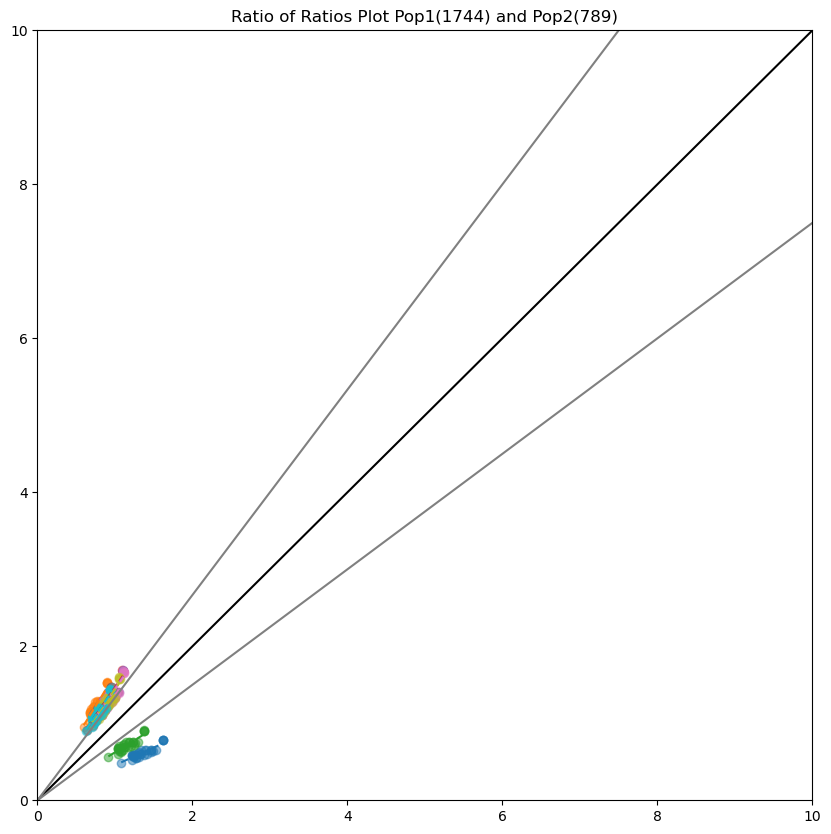

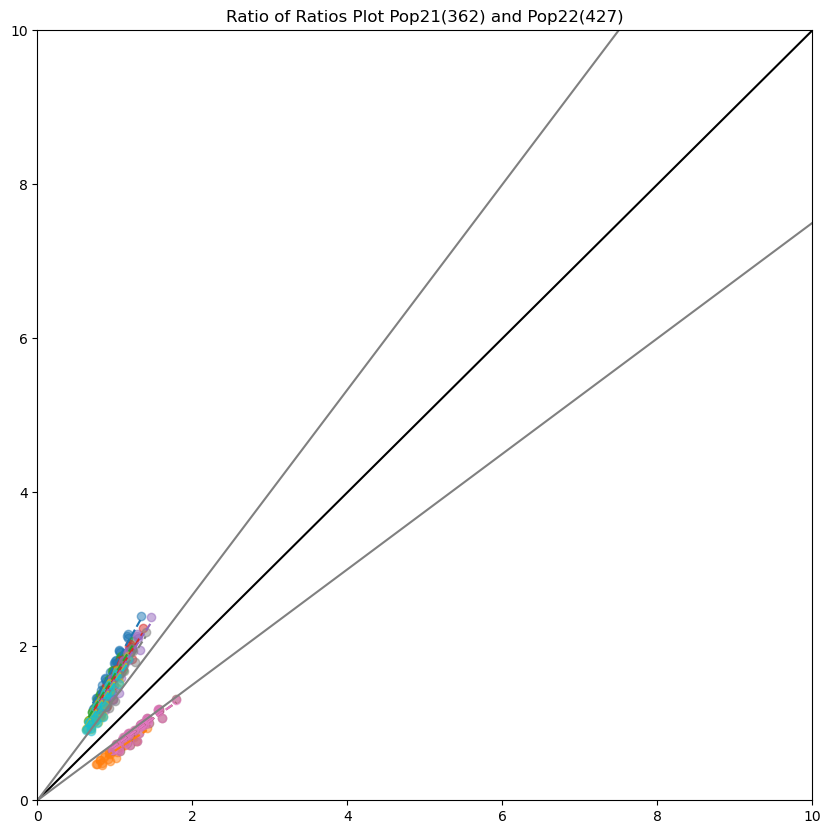

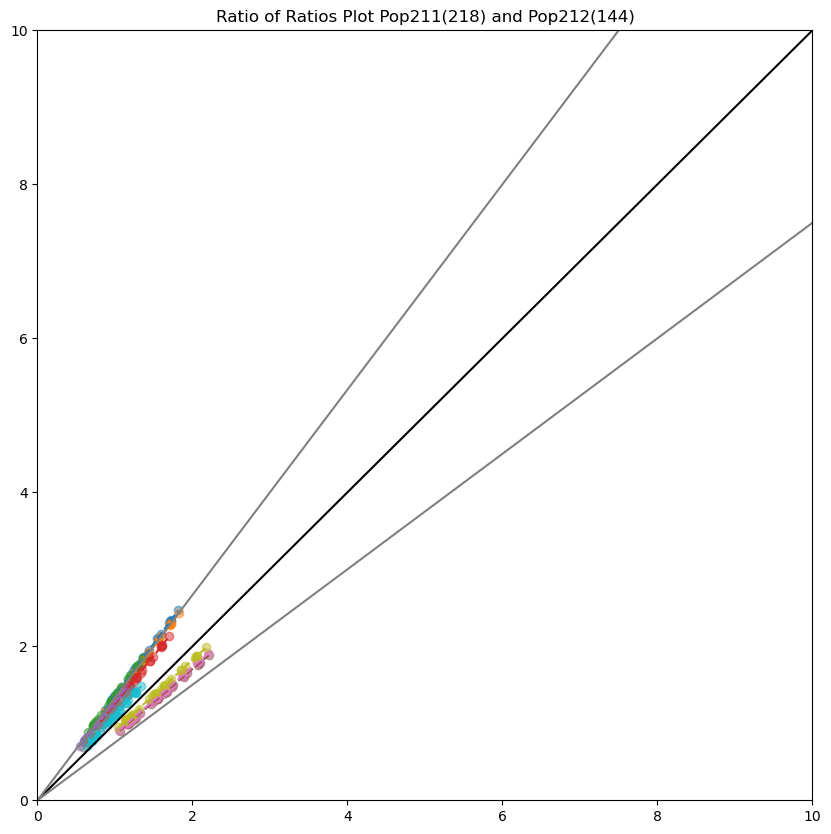

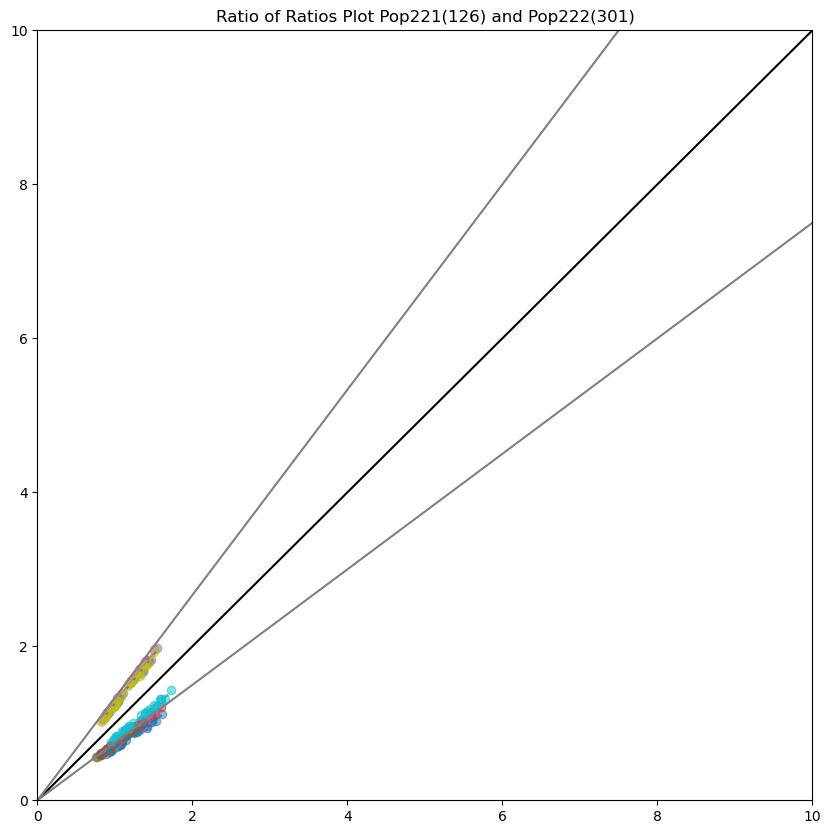

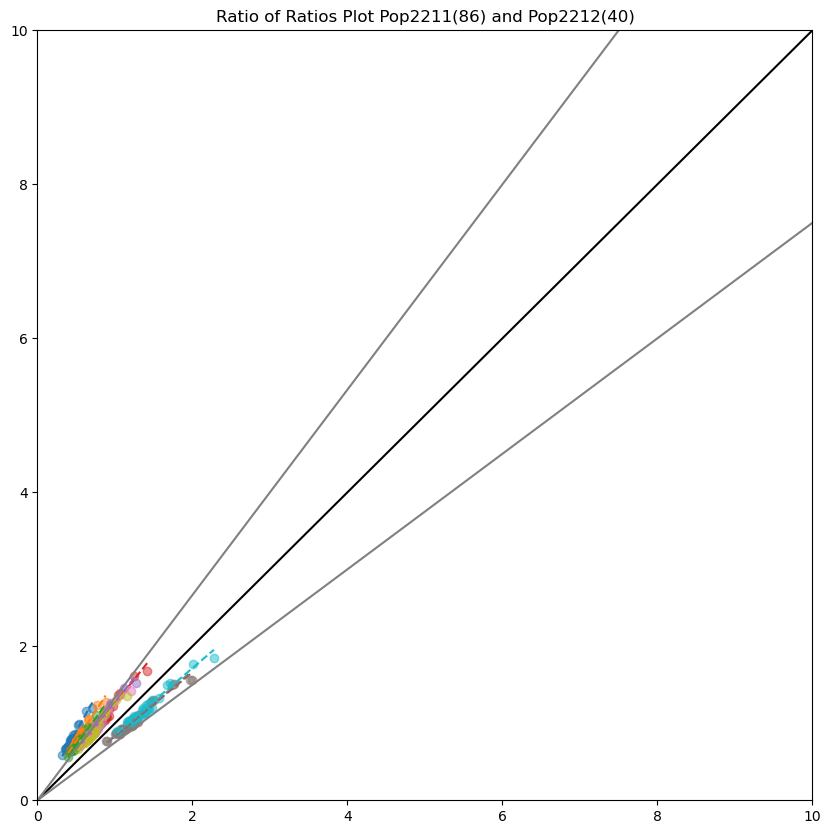

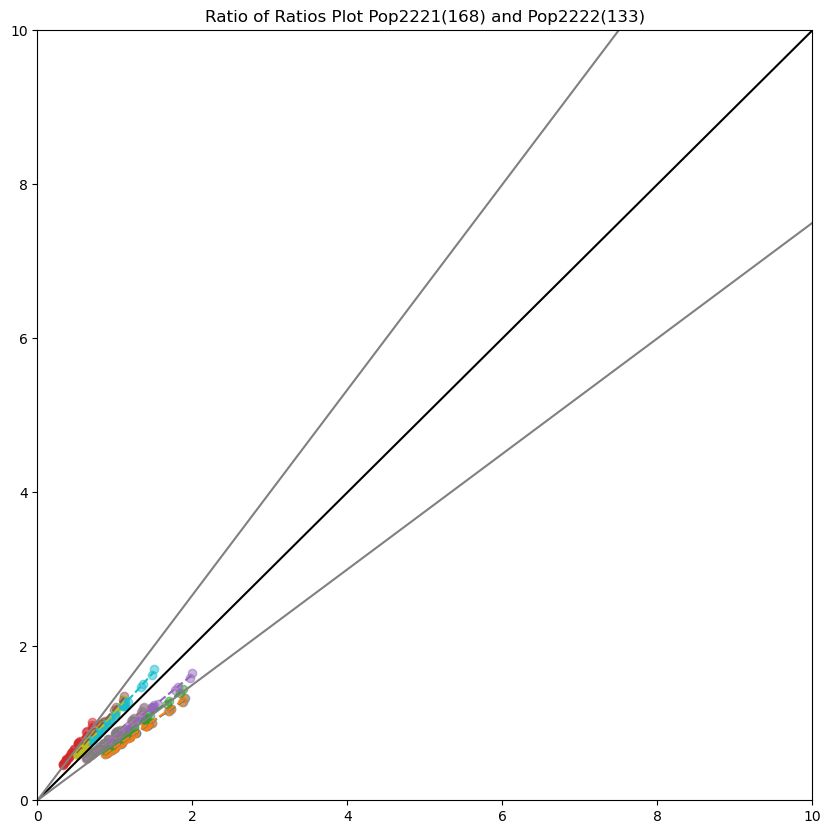

In [38]:
equi_bins_populations = recursive_em_split_new(all_data_no_WGS, cells, consensus_threshold=0.9, min_consensus=0.3, num_seeds=50, threshold=3/4, max_depth=10, name="Pop")

In [39]:
stop

NameError: name 'stop' is not defined

In [ ]:
final_populations_A = recursive_em_split_new(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="A"
)

final_populations_B = recursive_em_split_new(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="B"
)

final_populations_C = recursive_em_split_new(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="C"
)

final_populations_D = recursive_em_split_new(
    all_data, cells, 
    threshold=3/4, max_depth=10, name="D"
)

In [ ]:
pop_no_WGS_dict = reassign_cells(all_data_no_WGS, equi_bins_populations)

In [ ]:
A_dict = reassign_cells(all_data, final_populations_A)
B_dict = reassign_cells(all_data, final_populations_B)
C_dict = reassign_cells(all_data, final_populations_C)
D_dict = reassign_cells(all_data, final_populations_D)

In [ ]:
A_dict.keys(), B_dict.keys()

In [ ]:
overlap_df = plot_overlap_matrix_figure(A_dict, B_dict, name1="A", name2="B")

In [ ]:
overlap_df = plot_overlap_matrix_figure(A_dict, C_dict, name1="A", name2="C")

In [ ]:
overlap_df = plot_overlap_matrix_figure(A_dict, D_dict, name1="A", name2="D")

In [ ]:
overlap_df = plot_overlap_matrix_figure(B_dict, C_dict, name1="B", name2="C")

In [ ]:
overlap_df = plot_overlap_matrix_figure(B_dict, D_dict, name1="B", name2="D")

In [ ]:
overlap_df = plot_overlap_matrix_figure(D_dict, C_dict, name1="D", name2="C")

In [ ]:
from copy_number import (
    make_unif_dict, 
    compute_read_counts_relative_to_normal,
    compute_average_segment_counts, 
    compute_optimal_ploidy_and_profile,
    create_copy_number_matrix_fast
)
print("=== Population Set A Analysis ===")
avg_counts_A, ratios_A, normal_A = compute_average_segment_counts(all_data, A_dict, data)
relative_counts_A = compute_read_counts_relative_to_normal(all_data, A_dict, normal_A)
print("=== Population Set B Analysis ===")
avg_counts_B, ratios_B, normal_B = compute_average_segment_counts(all_data, B_dict, data)
relative_counts_B = compute_read_counts_relative_to_normal(all_data, B_dict, normal_B)
print("=== Population Set C Analysis ===")
avg_counts_C, ratios_C, normal_C = compute_average_segment_counts(all_data, C_dict, data)
relative_counts_C = compute_read_counts_relative_to_normal(all_data, C_dict, normal_C)
print("=== Population Set D Analysis ===")
avg_counts_D, ratios_D, normal_D = compute_average_segment_counts(all_data, D_dict, data)
relative_counts_D = compute_read_counts_relative_to_normal(all_data, D_dict, normal_D)



In [ ]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

# Get all population ratio columns (excluding normal population) for B
pop_ratio_cols_B = [col for col in ratios_B.columns if col.endswith('_ratio') and col != f"{normal_B}_ratio"]

# Store results
ploidy_results_B = {}
profile_dfs_B = {}

print(f"Normal population: {normal_B}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_B]}")

for pop_col in pop_ratio_cols_B:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_B, 
        relative_counts_B,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_B[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_B[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")

# For Population Set C
pop_ratio_cols_C = [col for col in ratios_C.columns if col.endswith('_ratio') and col != f"{normal_C}_ratio"]
ploidy_results_C = {}
profile_dfs_C = {}

print(f"Normal population: {normal_C}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_C]}")

for pop_col in pop_ratio_cols_C:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_C, 
        relative_counts_C,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_C[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_C[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# Get all population ratio columns (excluding normal population) for D
pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

# Store results
ploidy_results_D = {}
profile_dfs_D = {}

print(f"Normal population: {normal_D}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

for pop_col in pop_ratio_cols_D:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_D, 
        relative_counts_D,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_D[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_D[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")




In [ ]:
from copy_number import create_copy_number_matrix_fast
from visualization import plot_copy_number_heatmap, plot_overlap_matrix_figure

# Then you can use these functions in your analysis:

# Create heatmaps for both population sets
print("=== Creating Copy Number Heatmaps ===")

# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

# For Population Set B
heatmap_df_B, cell_mapping_B, boundaries_B, segment_info_B = create_copy_number_matrix_fast(
    all_data, 
    B_dict, 
    ratios_B, 
    {f"{pop}_ratio": ploidy_results_B[pop]['optimal_multiplier'] for pop in ploidy_results_B.keys()}, 
    normal_B
)

plot_copy_number_heatmap(
    heatmap_df_B, 
    boundaries_B, 
    segment_info_B,
    title="Copy Number Heatmap: Population Set B"
) 

# For Population Set C
heatmap_df_C, cell_mapping_C, boundaries_C, segment_info_C = create_copy_number_matrix_fast(
    all_data, 
    C_dict, 
    ratios_C, 
    {f"{pop}_ratio": ploidy_results_C[pop]['optimal_multiplier'] for pop in ploidy_results_C.keys()}, 
    normal_C
)       
plot_copy_number_heatmap(
    heatmap_df_C, 
    boundaries_C, 
    segment_info_C,
    title="Copy Number Heatmap: Population Set C"
)

# For Population Set D
heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
    all_data, 
    D_dict, 
    ratios_D, 
    {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()}, 
    normal_D
)

print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_D, 
    boundaries_D, 
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

In [ ]:
# Get all population ratio columns (excluding normal population) for A
pop_ratio_cols_A = [col for col in ratios_A.columns if col.endswith('_ratio') and col != f"{normal_A}_ratio"]

# Store results
ploidy_results_A = {}
profile_dfs_A = {}

print(f"Normal population: {normal_A}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_A]}")

for pop_col in pop_ratio_cols_A:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_A, 
        relative_counts_A,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_A[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_A[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# For Population Set A
heatmap_df_A, cell_mapping_A, boundaries_A, segment_info_A = create_copy_number_matrix_fast(
    all_data, 
    A_dict, 
    ratios_A, 
    {f"{pop}_ratio": ploidy_results_A[pop]['optimal_multiplier'] for pop in ploidy_results_A.keys()}, 
    normal_A
)

print(f"Heatmap A matrix dimensions: {heatmap_df_A.shape[0]} segments × {heatmap_df_A.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_A, 
    boundaries_A, 
    segment_info_A,
    title="Copy Number Heatmap: Population Set A"
)

In [ ]:
# Get all population ratio columns (excluding normal population) for D
pop_ratio_cols_D = [col for col in ratios_D.columns if col.endswith('_ratio') and col != f"{normal_D}_ratio"]

# Store results
ploidy_results_D = {}
profile_dfs_D = {}

print(f"Normal population: {normal_D}")
print(f"Populations to optimize: {[col.replace('_ratio', '') for col in pop_ratio_cols_D]}")

for pop_col in pop_ratio_cols_D:
    pop_name = pop_col.replace('_ratio', '')
    print(f"\n{'='*50}")
    print(f"Optimizing ploidy for population: {pop_name}")
    
    # Compute optimal ploidy
    optimal_m, min_cost, results_df, cost_results, _ = compute_optimal_ploidy_and_profile(
        ratios_D, 
        relative_counts_D,
        pop_col, 
        m_range=[1.5, 6], 
        step_size=0.1
    )
    
    # Store results
    ploidy_results_D[pop_name] = {
        'optimal_multiplier': optimal_m,
        'min_cost': min_cost,
        'cost_results': cost_results
    }
    profile_dfs_D[pop_name] = results_df
    
    print(f"Optimal multiplier for {pop_name}: {optimal_m:.3f}")


# For Population Set D
heatmap_df_D, cell_mapping_D, boundaries_D, segment_info_D = create_copy_number_matrix_fast(
    all_data, 
    D_dict, 
    ratios_D, 
    {f"{pop}_ratio": ploidy_results_D[pop]['optimal_multiplier'] for pop in ploidy_results_D.keys()}, 
    normal_D
)

print(f"Heatmap D matrix dimensions: {heatmap_df_D.shape[0]} segments × {heatmap_df_D.shape[1]} cells")

plot_copy_number_heatmap(
    heatmap_df_D, 
    boundaries_D, 
    segment_info_D,
    title="Copy Number Heatmap: Population Set D"
)

In [ ]:
# # Save population assignments A_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_new_population_assignments_A.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in A_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")

# #Save population assignments B_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_new_population_assignments_B.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in B_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")

# #Save population assignments C_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_new_population_assignments_C.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in C_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")

# #Save population assignments D_dict to a text file
# output_file = f"../data/{tumor}/{tumor}_new_population_assignments_D.txt"
# with open(output_file, 'w') as f:
#     #header
#     f.write("cell\tpopulation\n")
#     for pop_name, details in D_dict.items():
#         cell_list = details['cells']
#         for cell in cell_list:
#             f.write(f"{cell}\t{pop_name}\n")

#Save population assignments pop_no_WGS_dict to a text file
output_file = f"../data/{tumor}/{tumor}_population_assignments_equi_bins.txt"
with open(output_file, 'w') as f:
    #header
    f.write("cell\tpopulation\n")
    for pop_name, details in pop_no_WGS_dict.items():
        cell_list = details['cells']
        for cell in cell_list:
            f.write(f"{cell}\t{pop_name}\n")